In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [8]:
df = pd.read_csv("/content/car_dataset.csv (1).xls")

In [9]:
df.head()

,car_id,brand,model,year,segment,body_type,fuel_type,transmission,engine_cc,power_hp,fuel_economy_mpg,seats,km_driven,num_owners,condition,accident_history,color,city,price_usd
0,1,Hyundai,i20,2012,Hatchback,Hatchback,Diesel,Manual,1320,78,42.0,5,120639,1,Good,0,Brown,Mumbai,1460.0
1,2,Volkswagen,Polo,2021,Hatchback,Hatchback,Petrol,Automatic,1000,116,35.9,5,39084,1,Good,0,Blue,Bengaluru,7710.0
2,3,Volkswagen,Golf,2020,Hatchback,Hatchback,Petrol,Automatic,1400,136,32.7,5,39194,1,Good,0,Black,Kolkata,11100.0
3,4,Tata,Nexon,2019,SUV,SUV,Diesel,Manual,1320,115,30.5,5,69792,2,Good,0,Blue,Mumbai,4240.0
4,5,Mahindra,Scorpio,2024,SUV,SUV,Diesel,Manual,2420,148,23.0,7,9464,1,Good,0,Green,Chennai,17960.0


In [10]:
df.tail()

,car_id,brand,model,year,segment,body_type,fuel_type,transmission,engine_cc,power_hp,fuel_economy_mpg,seats,km_driven,num_owners,condition,accident_history,color,city,price_usd
175,176,Chevrolet,Malibu,2021,Midsize,Sedan,Petrol,Automatic,1500,154,29.9,5,39829,2,Excellent,0,Brown,Kolkata,13740.0
176,177,Chevrolet,Silverado,2013,Truck,Pickup,Diesel,Automatic,5830,407,21.9,5,94700,1,Good,0,Black,Delhi,5900.0
177,178,Nissan,Rogue,2023,SUV,SUV,Petrol,Manual,2500,186,30.7,5,18977,1,Good,0,Silver,Bengaluru,18960.0
178,179,Hyundai,Tucson,2019,SUV,SUV,CNG,Automatic,2500,181,29.5,5,98586,1,Fair,0,Blue,Hyderabad,7730.0
179,180,Maruti Suzuki,Ertiga,2023,MPV,MPV,CNG,Automatic,1500,97,25.7,7,29724,1,Fair,0,Black,Mumbai,7970.0


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_id            180 non-null    int64  
 1   brand             180 non-null    object 
 2   model             180 non-null    object 
 3   year              180 non-null    int64  
 4   segment           180 non-null    object 
 5   body_type         180 non-null    object 
 6   fuel_type         180 non-null    object 
 7   transmission      180 non-null    object 
 8   engine_cc         180 non-null    int64  
 9   power_hp          180 non-null    int64  
 10  fuel_economy_mpg  180 non-null    float64
 11  seats             180 non-null    int64  
 12  km_driven         180 non-null    int64  
 13  num_owners        180 non-null    int64  
 14  condition         180 non-null    object 
 15  accident_history  180 non-null    int64  
 16  color             180 non-null    object 
 1

In [12]:
df.duplicated().sum()

np.int64(0)

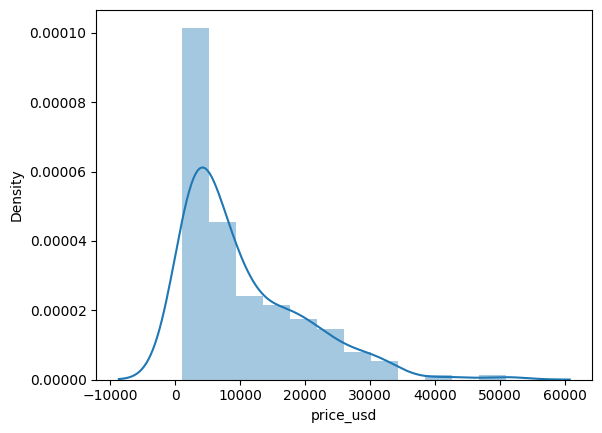

In [19]:
# Univariate Analysis: Car Price
sns.distplot(df['price_usd'])
plt.show()

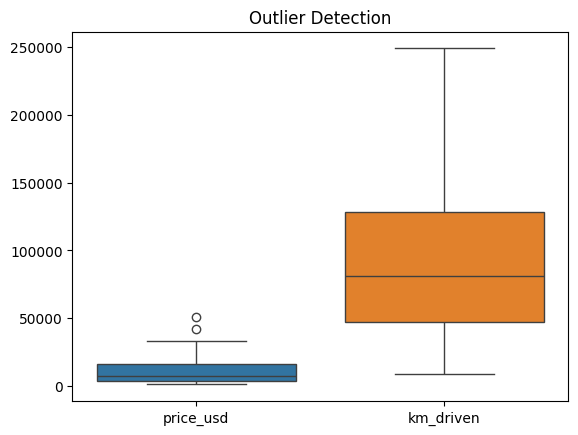

In [26]:
# Outlier Detection
sns.boxplot(df[['price_usd','km_driven']])
plt.title("Outlier Detection")
plt.show()

In [27]:
# Outlier Treatment
for col in ['price_usd','km_driven']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = np.where(
        df[col] > upper, upper,
        np.where(df[col] < lower, lower, df[col])
    )

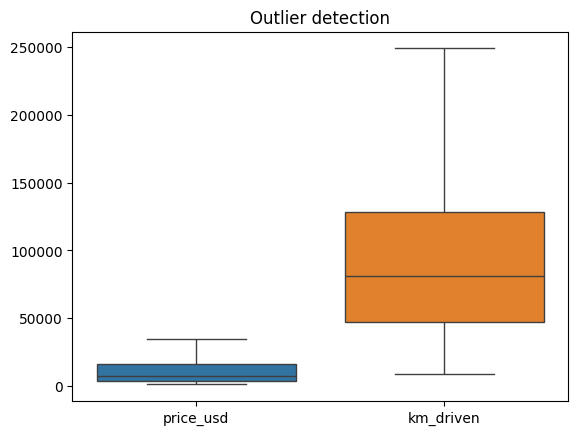

In [28]:
sns.boxplot(df[ ['price_usd','km_driven']])
plt.title("Outlier detection")
plt.show()

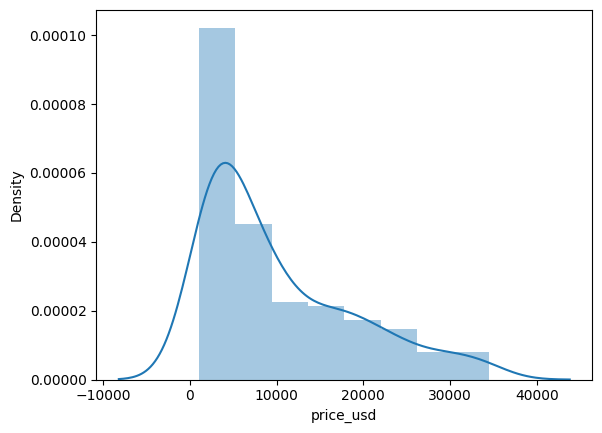

In [29]:
# Univariate Analysis: Car Price
sns.distplot(df['price_usd'])
plt.show()

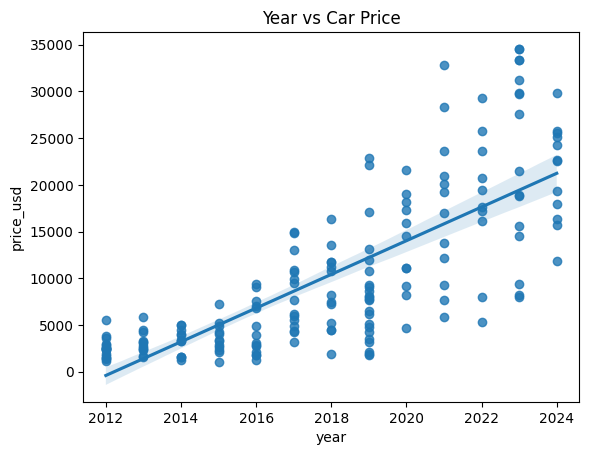

In [30]:
# Bivariate Analysis
sns.regplot(x=df['year'], y=df['price_usd'])
plt.title("Year vs Car Price")
plt.show()